# Results and Analysis

This notebook contains the code to import our models, generate predictions, create performance summaries, plot ROC and PRC, and generate GradCAM visualizations.

In [1]:
import numpy as np
from sklearn.metrics import cohen_kappa_score, precision_score, recall_score, f1_score, roc_curve, auc, precision_recall_curve
from sklearn.preprocessing import label_binarize
import torch
import torch.nn.functional as F
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
import torchvision.models as models
from torch.utils.data import DataLoader, Subset, TensorDataset
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, cohen_kappa_score
from collections import Counter

import warnings
warnings.filterwarnings('ignore')

In [ ]:
x_train = torch.load('data/x_train.pt')
y_train = torch.load('data/y_train.pt')
x_test = torch.load('data/x_test.pt')
y_test = torch.load('data/y_test.pt')

train_dataset = TensorDataset(x_train, y_train)
test_dataset = TensorDataset(x_test, y_test)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## Load Trained Models

Here we redefine our models (just as in our previous notebooks) and import the saved models weights, which we saved to the models folder.

In [ ]:
# Baseline CNN

class CNN(nn.Module):
    def __init__(self, num_classes=5):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.3)

        self.fc1 = nn.Linear(128 * 28 * 28, 256)
        self.fc2 = nn.Linear(256, num_classes)
        
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        
        return x

cnn_model = CNN().to(device)
cnn_model.load_state_dict(torch.load('models/cnn_state_dict.pth', map_location=device))

<All keys matched successfully>

In [ ]:
# ResNet

def create_resnet(num_classes=5, dropout_rate=0.5):
    model = models.resnet50(weights='DEFAULT')
    
    in_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Dropout(dropout_rate),
        nn.Linear(in_features, 512),
        nn.ReLU(),
        nn.Dropout(dropout_rate/2),
        nn.Linear(512, num_classes)
    )
    return model

resnet_model = create_resnet(dropout_rate=0.5)
resnet_model.to(device)
resnet_model.load_state_dict(torch.load('models/resnet_state_dict.pth', map_location=device))

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 154MB/s]


<All keys matched successfully>

In [ ]:
# EfficientNet

def create_efficientnet(num_classes=5, dropout_rate=0.3, verbose=False):
    model = models.efficientnet_b4(weights='DEFAULT')
    
    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(dropout_rate),
        nn.Linear(in_features, 512),
        nn.ReLU(),
        nn.Dropout(dropout_rate),
        nn.Linear(512, num_classes)
    )
    return model

efficientnet_model = create_efficientnet(dropout_rate=0.3)
efficientnet_model.to(device)
efficientnet_model.load_state_dict(torch.load('models/efficientnet_state_dict.pth', map_location=device))

Downloading: "https://download.pytorch.org/models/efficientnet_b4_rwightman-23ab8bcd.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b4_rwightman-23ab8bcd.pth
100%|██████████| 74.5M/74.5M [00:00<00:00, 88.3MB/s]


<All keys matched successfully>

## Performance Analysis

This code generates test predictions for each model and stores the evaluation metrics in the dictionary "results".

In [ ]:
class_names = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']
models = {
    'CNN': cnn_model,
    'EfficientNet-B4': efficientnet_model,
    'ResNet-50': resnet_model
}

results = {}
for model_name, model in models.items():
    model.eval()
    all_preds = []
    all_probs = []
    all_true = []

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1) # Probabilities (5 for each example)
            preds = torch.argmax(outputs, dim=1) # Predicted class labels (0-4)
            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_true.extend(labels.cpu().numpy())
    
    qwk = cohen_kappa_score(all_true, all_preds, weights='quadratic')
    precision = precision_score(all_true, all_preds, average='weighted', zero_division=0)
    recall = recall_score(all_true, all_preds, average='weighted', zero_division=0)
    f1 = f1_score(all_true, all_preds, average='weighted', zero_division=0)

    results[model_name] = {
        'probabilities': all_probs,
        'predictions': all_preds,
        'true_labels': all_true,
        'quadratic_weighted_kappa': qwk,
        'precision': precision,
        'recall': recall,
        'f1_score': f1
    }


### Overall Performance

First, we'll analyze our each model by our four metrics: quadratic weighted kappa, precision, recall, and F1-score.

In [8]:
def create_performance_summary(results):
    summary_data = []
    for model_name, metrics in results.items():
        summary_data.append({
            'Model': model_name,
            'Quadratic Weighted Kappa': round(metrics['quadratic_weighted_kappa'], 4),
            'Precision': round(metrics['precision'], 4),
            'Recall': round(metrics['recall'], 4),
            'F1 Score': round(metrics['f1_score'], 4)
        })
    return pd.DataFrame(summary_data)

In [9]:
performance_df = create_performance_summary(results)

# Save as markdown files
with open('performance_table.md', 'w') as f:
   f.write(performance_df.to_markdown(index=False))

# Display results
print("OVERALL PERFORMANCE SUMMARY")
print("=" * 50)
display(performance_df)

OVERALL PERFORMANCE SUMMARY


,Model,Quadratic Weighted Kappa,Precision,Recall,F1 Score
0,CNN,0.7074,0.7217,0.7135,0.7120
1,EfficientNet-B4,0.8339,0.7956,0.7749,0.7796
2,ResNet-50,0.8136,0.7582,0.7653,0.7606


### Class-Wise Performance

Since our dataset is imbalanced and different classes require different levels of precision and recall, we need to inspect model performance for each class individually.

In [10]:
def create_classwise_summary(results):
    metrics_data = {class_name: {} for class_name in class_names}
    
    for model_name, metrics in results.items():
        y_true = metrics['true_labels']
        y_pred = metrics['predictions']
        
        report = classification_report(
            y_true, y_pred,
            target_names=class_names,
            output_dict=True,
            zero_division=0
        )
        
        for class_name in class_names:
            metrics_data[class_name][f'{model_name} - Precision'] = round(report[class_name]['precision'], 4)
            metrics_data[class_name][f'{model_name} - Recall'] = round(report[class_name]['recall'], 4)
            metrics_data[class_name][f'{model_name} - F1 Score'] = round(report[class_name]['f1-score'], 4)
    
    df = pd.DataFrame(metrics_data).T  # Classes as rows
    return df


:::{dropdown} Code Explanation
```python
def create_classwise_summary(results):
    metrics_data = {class_name: {} for class_name in class_names}
```
Initializes an empty dictionary where each key is a class name (e.g., 'No DR', 'Mild', etc.), and each value will hold performance metrics for each model.

```python
    for model_name, metrics in results.items():
        y_true = metrics['true_labels']
        y_pred = metrics['predictions']
        
        report = classification_report(
            y_true, y_pred,
            target_names=class_names,
            output_dict=True,
            zero_division=0
        )
```
Loops over each model's results, extracts the true and predicted labels, and generates a classification report with precision, recall, and F1-score per class. Setting `output_dict=True` allows programmatic access to these values.

```python
        for class_name in class_names:
            metrics_data[class_name][f'{model_name} - Precision'] = round(report[class_name]['precision'], 4)
            metrics_data[class_name][f'{model_name} - Recall'] = round(report[class_name]['recall'], 4)
            metrics_data[class_name][f'{model_name} - F1 Score'] = round(report[class_name]['f1-score'], 4)
```
For each class, extracts that model's precision, recall, and F1-score from the report and stores them in the dictionary under keys formatted with the model name.

```python
    df = pd.DataFrame(metrics_data).T  # Classes as rows
    return df
```
Converts the dictionary into a pandas DataFrame and transposes it so that classes appear as rows and metrics per model are columns. Returns the summary table.
:::


In [ ]:
classwise_df = create_classwise_summary(results)
 
with open('classwise_table.md', 'w') as f:
   f.write(classwise_df.to_markdown())

# Display results
print("\nCLASS-WISE PERFORMANCE")
print("=" * 50)
display(classwise_df)


CLASS-WISE PERFORMANCE


,CNN - Precision,CNN - Recall,CNN - F1 Score,EfficientNet-B4 - Precision,EfficientNet-B4 - Recall,EfficientNet-B4 - F1 Score,ResNet-50 - Precision,ResNet-50 - Recall,ResNet-50 - F1 Score
No DR,0.9199,0.9224,0.9212,0.9481,0.9612,0.9546,0.9401,0.9557,0.9478
Mild,0.3565,0.5541,0.4339,0.4632,0.5946,0.5207,0.4872,0.5135,0.5000
Moderate,0.6885,0.6300,0.6580,0.8013,0.6050,0.6895,0.7073,0.7250,0.7160
Severe,0.2826,0.3333,0.3059,0.3966,0.5897,0.4742,0.3913,0.2308,0.2903
Proliferative,0.3704,0.1695,0.2326,0.5238,0.5593,0.5410,0.4000,0.4068,0.4034


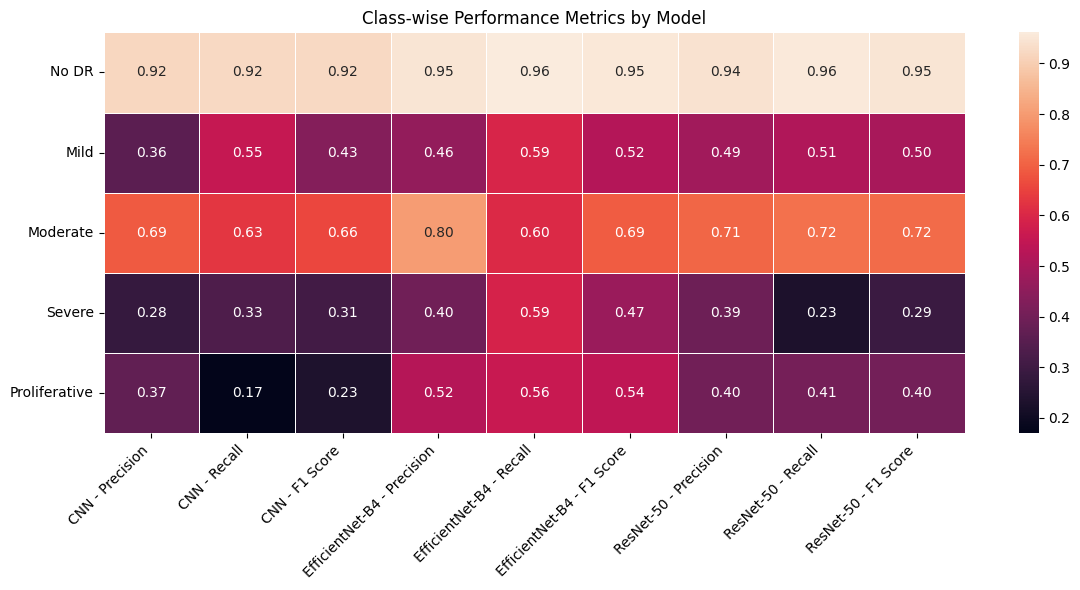

In [12]:
plt.figure(figsize=(12, 6))
sns.heatmap(classwise_df.astype(float), annot=True, fmt=".2f", linewidths=0.5, cbar=True)

plt.title("Class-wise Performance Metrics by Model")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## ROC (Receiver Operating Characteristic Curve) and PRC (Precision-Recall Curve)

In [13]:
def plot_multiclass_roc_prc(model_name, results_dict):
    y_true = np.array(results_dict[model_name]['true_labels'])
    y_pred = np.array(results_dict[model_name]['predictions'])

    y_true = np.array(results_dict[model_name]['true_labels'])
    y_pred = np.array(results_dict[model_name]['probabilities'])

    class_names = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']

    n_classes = len(np.unique(y_true))
    if class_names is None:
        class_names = [f"Class {i}" for i in range(n_classes)]

    # Binarize labels
    y_true_bin = label_binarize(y_true, classes=np.arange(n_classes))

    # Compute ROC and PRC
    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    precision = dict()
    recall = dict()
    prc_auc = dict()

    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

        precision[i], recall[i], _ = precision_recall_curve(y_true_bin[:, i], y_pred[:, i])
        prc_auc[i] = auc(recall[i], precision[i])

    # Plot
    plt.figure(figsize=(12, 5))

    # ROC Curve
    plt.subplot(1, 2, 1)
    for i in range(n_classes):
        plt.plot(fpr[i], tpr[i], label=f"{class_names[i]} (AUC = {roc_auc[i]:.2f})")
    plt.plot([0, 1], [0, 1], 'k--', alpha=0.4)
    plt.title(f"ROC Curve ({model_name})")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()

    # PRC Curve
    plt.subplot(1, 2, 2)
    for i in range(n_classes):
        plt.plot(recall[i], precision[i], label=f"{class_names[i]} (AUC = {prc_auc[i]:.2f})")
    plt.title(f"Precision-Recall Curve ({model_name})")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.legend()

    plt.tight_layout()
    plt.show()

:::{dropdown} Code Explanation
```python
def plot_multiclass_roc_prc(model_name, results_dict):
    y_true = np.array(results_dict[model_name]['true_labels'])
    y_pred = np.array(results_dict[model_name]['probabilities'])

    class_names = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']

    n_classes = len(np.unique(y_true))
    if class_names is None:
        class_names = [f"Class {i}" for i in range(n_classes)]

    y_true_bin = label_binarize(y_true, classes=np.arange(n_classes))
```
Prepares the data for plotting by extracting true labels and predicted probabilities for the selected model. Then it binarizes the true labels so ROC and PRC curves can be computed per class.

```python
    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    precision = dict()
    recall = dict()
    prc_auc = dict()

    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

        precision[i], recall[i], _ = precision_recall_curve(y_true_bin[:, i], y_pred[:, i])
        prc_auc[i] = auc(recall[i], precision[i])
```
Computes the false positive rate (FPR), true positive rate (TPR), and area under the curve (AUC) for both ROC and precision-recall curves for each class individually.

```python
    plt.figure(figsize=(12, 5))

    # ROC Curve
    plt.subplot(1, 2, 1)
    for i in range(n_classes):
        plt.plot(fpr[i], tpr[i], label=f"{class_names[i]} (AUC = {roc_auc[i]:.2f})")
    plt.plot([0, 1], [0, 1], 'k--', alpha=0.4)
    plt.title(f"ROC Curve ({model_name})")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
```
Creates the first subplot showing the ROC curve for each class, including the AUC score in the legend. A diagonal reference line is added for context.

```python
    # PRC Curve
    plt.subplot(1, 2, 2)
    for i in range(n_classes):
        plt.plot(recall[i], precision[i], label=f"{class_names[i]} (AUC = {prc_auc[i]:.2f})")
    plt.title(f"Precision-Recall Curve ({model_name})")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.legend()

    plt.tight_layout()
    plt.show()
```
Creates the second subplot showing the precision-recall curve per class with corresponding AUCs. Uses `tight_layout()` for spacing and `show()` to render the plots.
:::


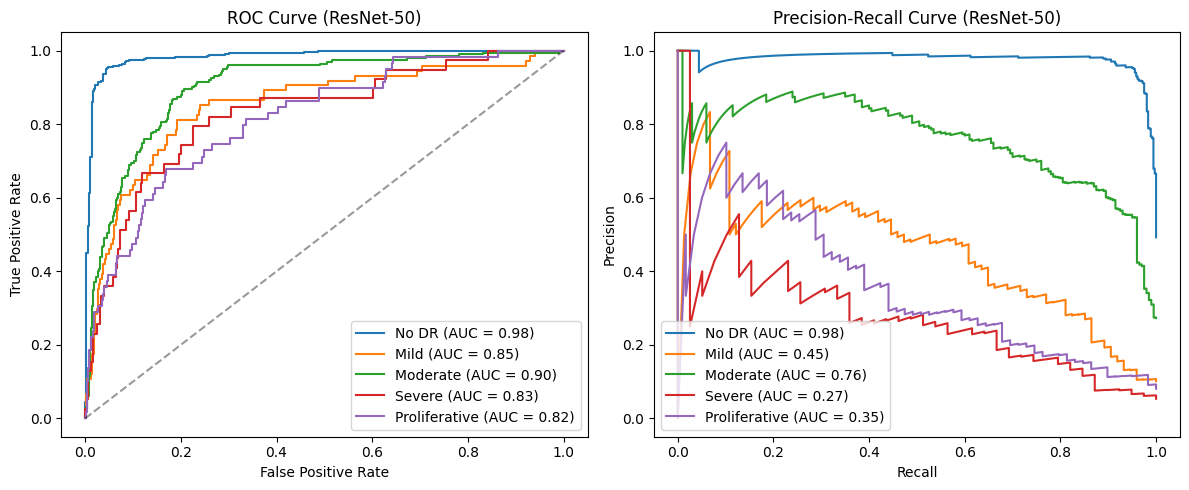

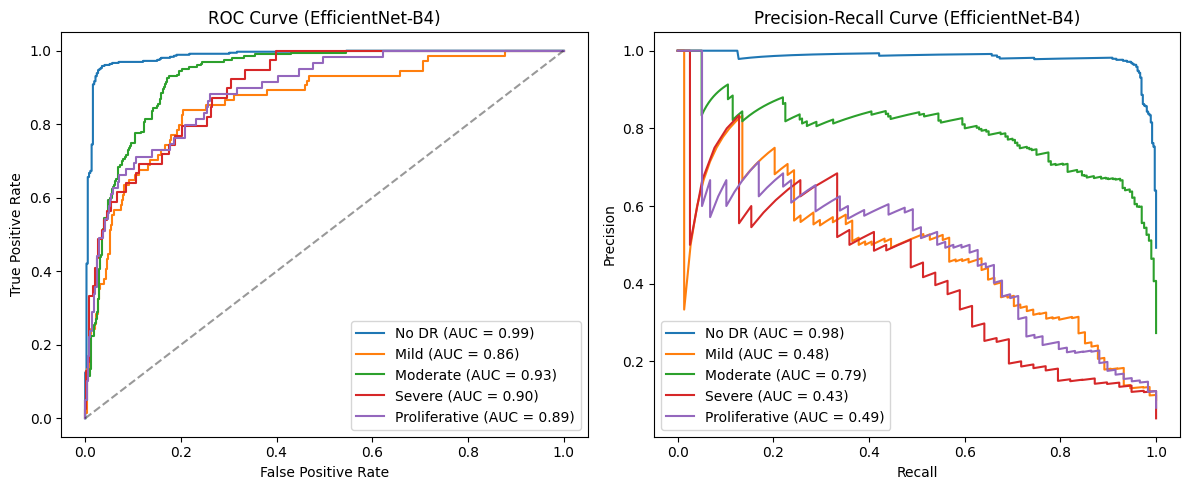

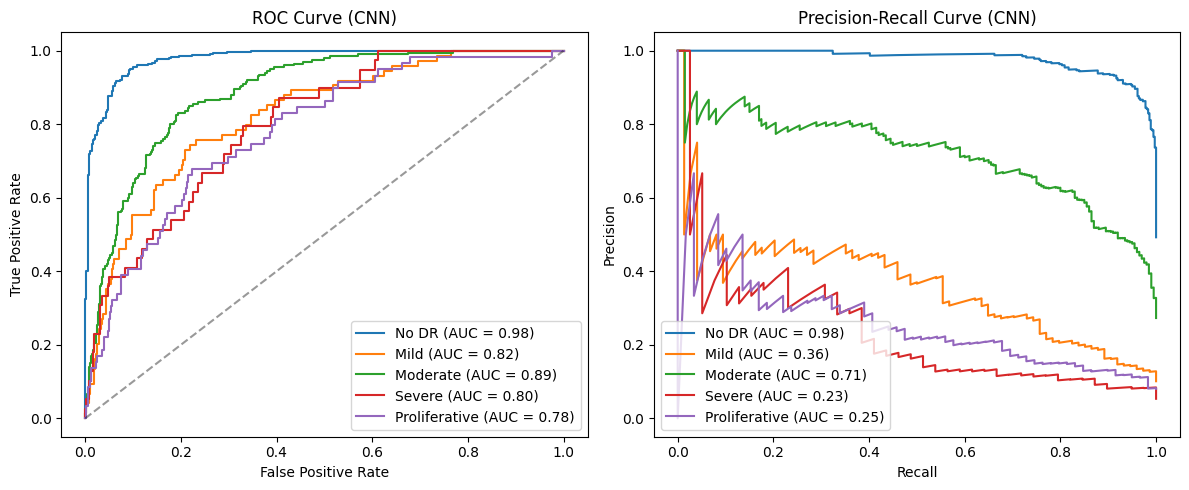

In [14]:
plot_multiclass_roc_prc('ResNet-50', results)
plot_multiclass_roc_prc('EfficientNet-B4', results)
plot_multiclass_roc_prc('CNN', results)

## Explainability and Feature Analysis

In [15]:
!pip install -q grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 68.7 MB/s eta 0:00:00:00:010:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.4 MB/s eta 0:00:00:00:01m0:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.6 MB/s eta 0:00:000:00:010:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 3.2 MB/s eta 0:00:00:00:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 26.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 10.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 48.6 MB/s eta 0:00:0000:0100:01


In [16]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

In [17]:
def show_gradcam(model, model_name, images, true_labels, target_layers, figsize=(15, 20)):   
    model.to(device)
    model.eval()
    
    with GradCAM(model=model, target_layers=target_layers) as cam:
        correct_class_indices = {}
        wrong_class_indices = {}

        # Collect correct and incorrect examples per class
        for i, label in enumerate(true_labels):
            class_val = label.item()
            if class_val not in [0, 1, 2, 3, 4]:
                continue

            input_tensor = images[i:i+1].to(device)
            with torch.no_grad():
                pred_class = torch.argmax(model(input_tensor)).item()

            if pred_class == class_val and class_val not in correct_class_indices:
                correct_class_indices[class_val] = i
            elif pred_class != class_val and class_val not in wrong_class_indices:
                wrong_class_indices[class_val] = i

            # Stop early if we found both examples for all classes
            if len(correct_class_indices) + len(wrong_class_indices) == 10:
                break

        # Determine what to plot
        plot_items = []
        for class_num in sorted(set(correct_class_indices.keys()).union(wrong_class_indices.keys())):
            if class_num in correct_class_indices:
                plot_items.append(('Correct', class_num, correct_class_indices[class_num]))
            if class_num in wrong_class_indices:
                plot_items.append(('Wrong', class_num, wrong_class_indices[class_num]))

        if not plot_items:
            print(f"No examples found for {model_name}")
            return

        fig, axes = plt.subplots(len(plot_items), 3, figsize=figsize)
        if len(plot_items) == 1:
            axes = axes.reshape(1, -1)

        for row, (status, class_num, i) in enumerate(plot_items):
            input_tensor = images[i:i+1].to(device)
            true_class = true_labels[i].item()
            with torch.no_grad():
                pred_class = torch.argmax(model(input_tensor)).item()

            # Target the correct class for GradCAM
            if status == 'Correct':
                target = [ClassifierOutputTarget(true_class)]
            else:
                target = [ClassifierOutputTarget(pred_class)]

            grayscale_cam = cam(input_tensor=input_tensor, targets=target)

            image_np = images[i].permute(1, 2, 0).cpu().numpy()
            image_np = np.clip(image_np, 0, 1)
            overlay = show_cam_on_image(image_np, grayscale_cam[0], use_rgb=True)

            axes[row, 0].imshow(image_np)
            axes[row, 0].set_title(f'True: {true_class}, Pred: {pred_class}')
            axes[row, 0].axis('off')

            axes[row, 1].imshow(grayscale_cam[0], cmap='jet')
            axes[row, 1].set_title(f'GradCAM ({status})')
            axes[row, 1].axis('off')

            axes[row, 2].imshow(overlay)
            axes[row, 2].set_title('Overlay')
            axes[row, 2].axis('off')

        plt.suptitle(f'{model_name} GradCAM: Correct vs Incorrect Predictions', fontsize=16, y=1.01)
        plt.savefig(f'{model_name}_gradcam.png', dpi=300, bbox_inches='tight')
        plt.tight_layout()
        plt.show()
        plt.close()


:::{dropdown} Code Explanation
```python
def show_gradcam(model, model_name, images, true_labels, target_layers, figsize=(15, 20)):   
    model.to(device)
    model.eval()
    
    with GradCAM(model=model, target_layers=target_layers) as cam:
```
Prepares the model for evaluation and initializes the GradCAM object, which will compute class-specific activation heatmaps using the specified target layers.

```python
        correct_class_indices = {}
        wrong_class_indices = {}

        # Collect correct and incorrect examples per class
        for i, label in enumerate(true_labels):
            class_val = label.item()
            if class_val not in [0, 1, 2, 3, 4]:
                continue

            input_tensor = images[i:i+1].to(device)
            with torch.no_grad():
                pred_class = torch.argmax(model(input_tensor)).item()

            if pred_class == class_val and class_val not in correct_class_indices:
                correct_class_indices[class_val] = i
            elif pred_class != class_val and class_val not in wrong_class_indices:
                wrong_class_indices[class_val] = i

            # Stop early if we found both examples for all classes
            if len(correct_class_indices) + len(wrong_class_indices) == 10:
                break
```
Loops through the dataset to find a single correct and incorrect prediction for each class (0–4). These will later be visualized to compare how the model attends to different regions during right vs wrong predictions.

```python
        plot_items = []
        for class_num in sorted(set(correct_class_indices.keys()).union(wrong_class_indices.keys())):
            if class_num in correct_class_indices:
                plot_items.append(('Correct', class_num, correct_class_indices[class_num]))
            if class_num in wrong_class_indices:
                plot_items.append(('Wrong', class_num, wrong_class_indices[class_num]))

        if not plot_items:
            print(f"No examples found for {model_name}")
            return
```
Assembles a list of examples to visualize: one correct and/or incorrect prediction per class. If no such examples were found, the function exits early.

```python
        fig, axes = plt.subplots(len(plot_items), 3, figsize=figsize)
        if len(plot_items) == 1:
            axes = axes.reshape(1, -1)
```
Creates a matplotlib figure with one row per example and three columns: original image, raw GradCAM heatmap, and overlay. Handles special case when there's only one row.

```python
        for row, (status, class_num, i) in enumerate(plot_items):
            input_tensor = images[i:i+1].to(device)
            true_class = true_labels[i].item()
            with torch.no_grad():
                pred_class = torch.argmax(model(input_tensor)).item()

            if status == 'Correct':
                target = [ClassifierOutputTarget(true_class)]
            else:
                target = [ClassifierOutputTarget(pred_class)]

            grayscale_cam = cam(input_tensor=input_tensor, targets=target)

            image_np = images[i].permute(1, 2, 0).cpu().numpy()
            image_np = np.clip(image_np, 0, 1)
            overlay = show_cam_on_image(image_np, grayscale_cam[0], use_rgb=True)
```
For each example, selects the appropriate target class (either true or predicted), computes the GradCAM heatmap, and prepares both the original image and the GradCAM overlay.

```python
            axes[row, 0].imshow(image_np)
            axes[row, 0].set_title(f'True: {true_class}, Pred: {pred_class}')
            axes[row, 0].axis('off')

            axes[row, 1].imshow(grayscale_cam[0], cmap='jet')
            axes[row, 1].set_title(f'GradCAM ({status})')
            axes[row, 1].axis('off')

            axes[row, 2].imshow(overlay)
            axes[row, 2].set_title('Overlay')
            axes[row, 2].axis('off')
```
Displays each image in three formats: original, raw GradCAM heatmap, and overlay. Titles indicate correctness and predicted class for interpretability.

```python
        plt.suptitle(f'{model_name} GradCAM: Correct vs Incorrect Predictions', fontsize=16, y=1.01)
        plt.savefig(f'{model_name}_gradcam.png', dpi=300, bbox_inches='tight')
        plt.tight_layout()
        plt.show()
        plt.close()
```
Adds a figure title, saves the plot to file, lays out subplots nicely, and renders the final visualization comparing model attention in correct and incorrect predictions.
:::


### CNN

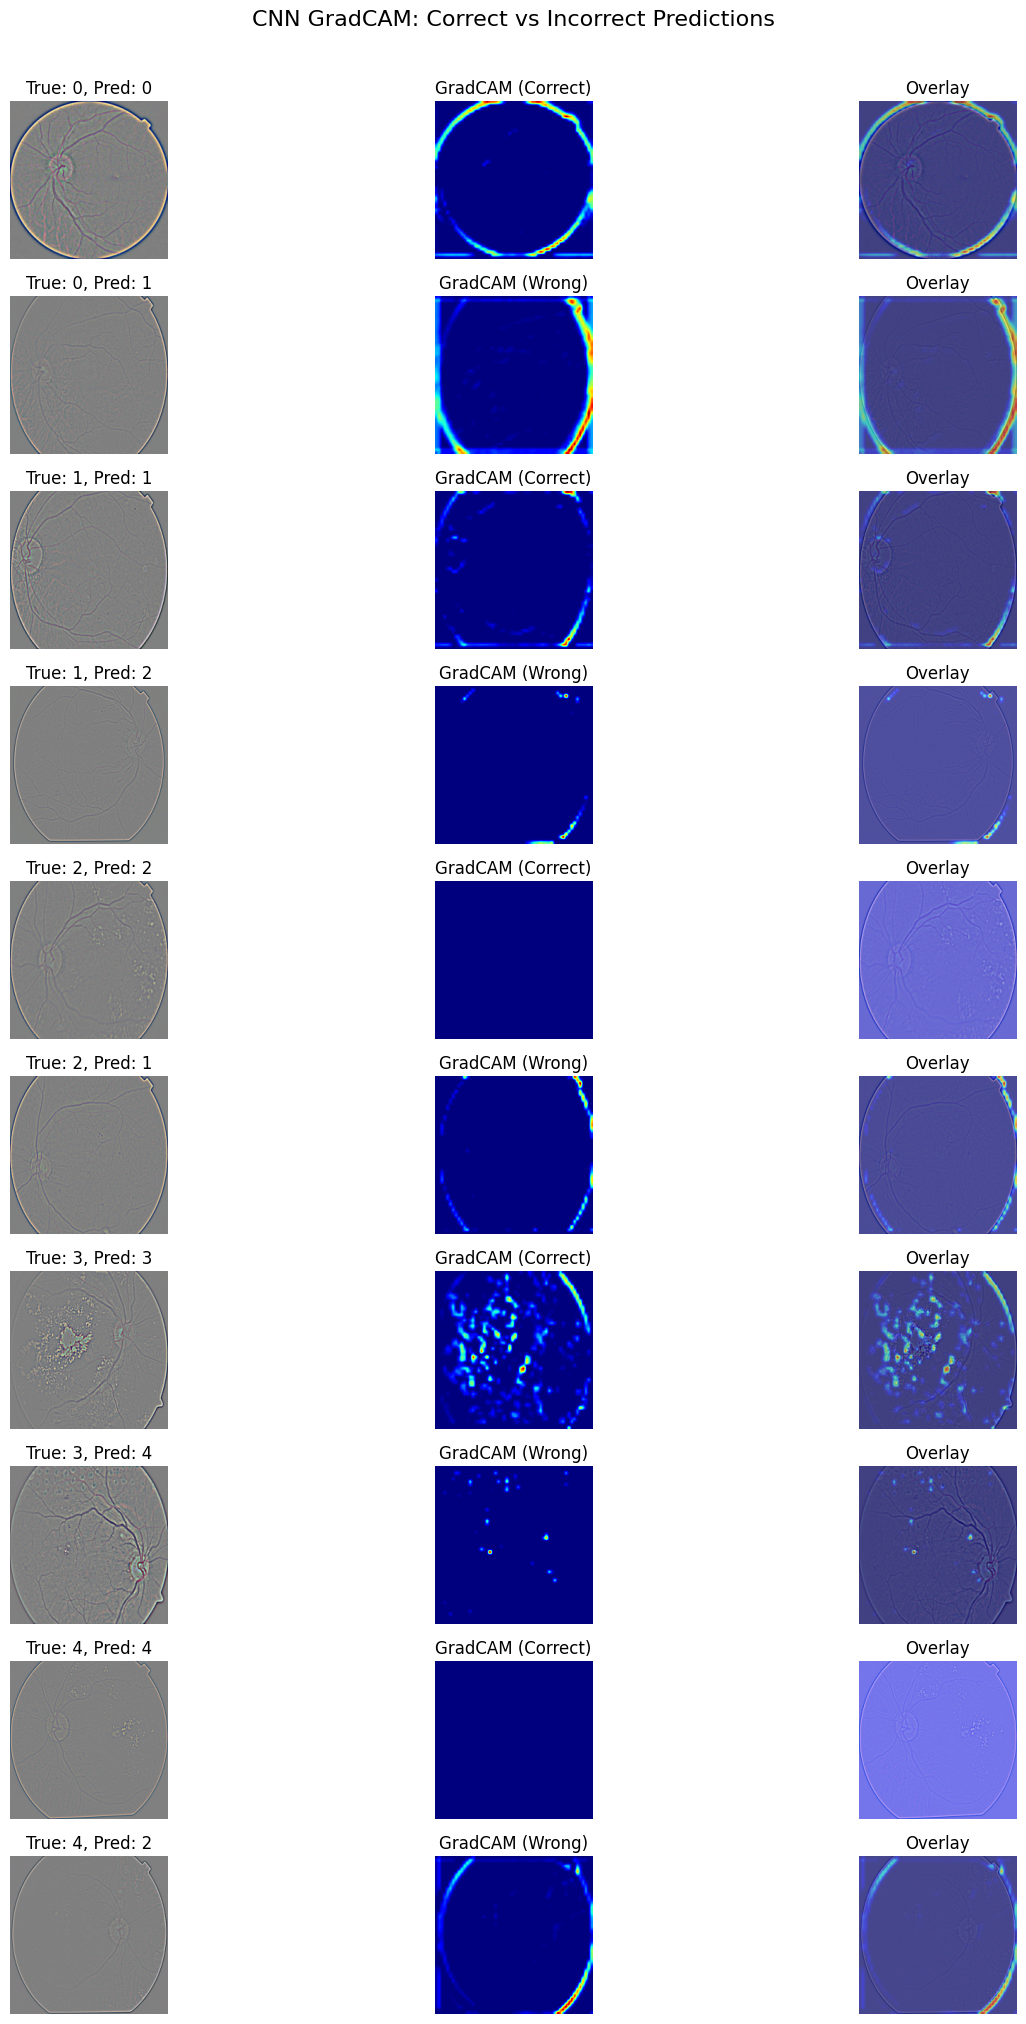

In [18]:
target_layers = [cnn_model.conv3]
cnn_cams = show_gradcam(cnn_model, 'CNN', x_train, y_train, target_layers)

### ResNet

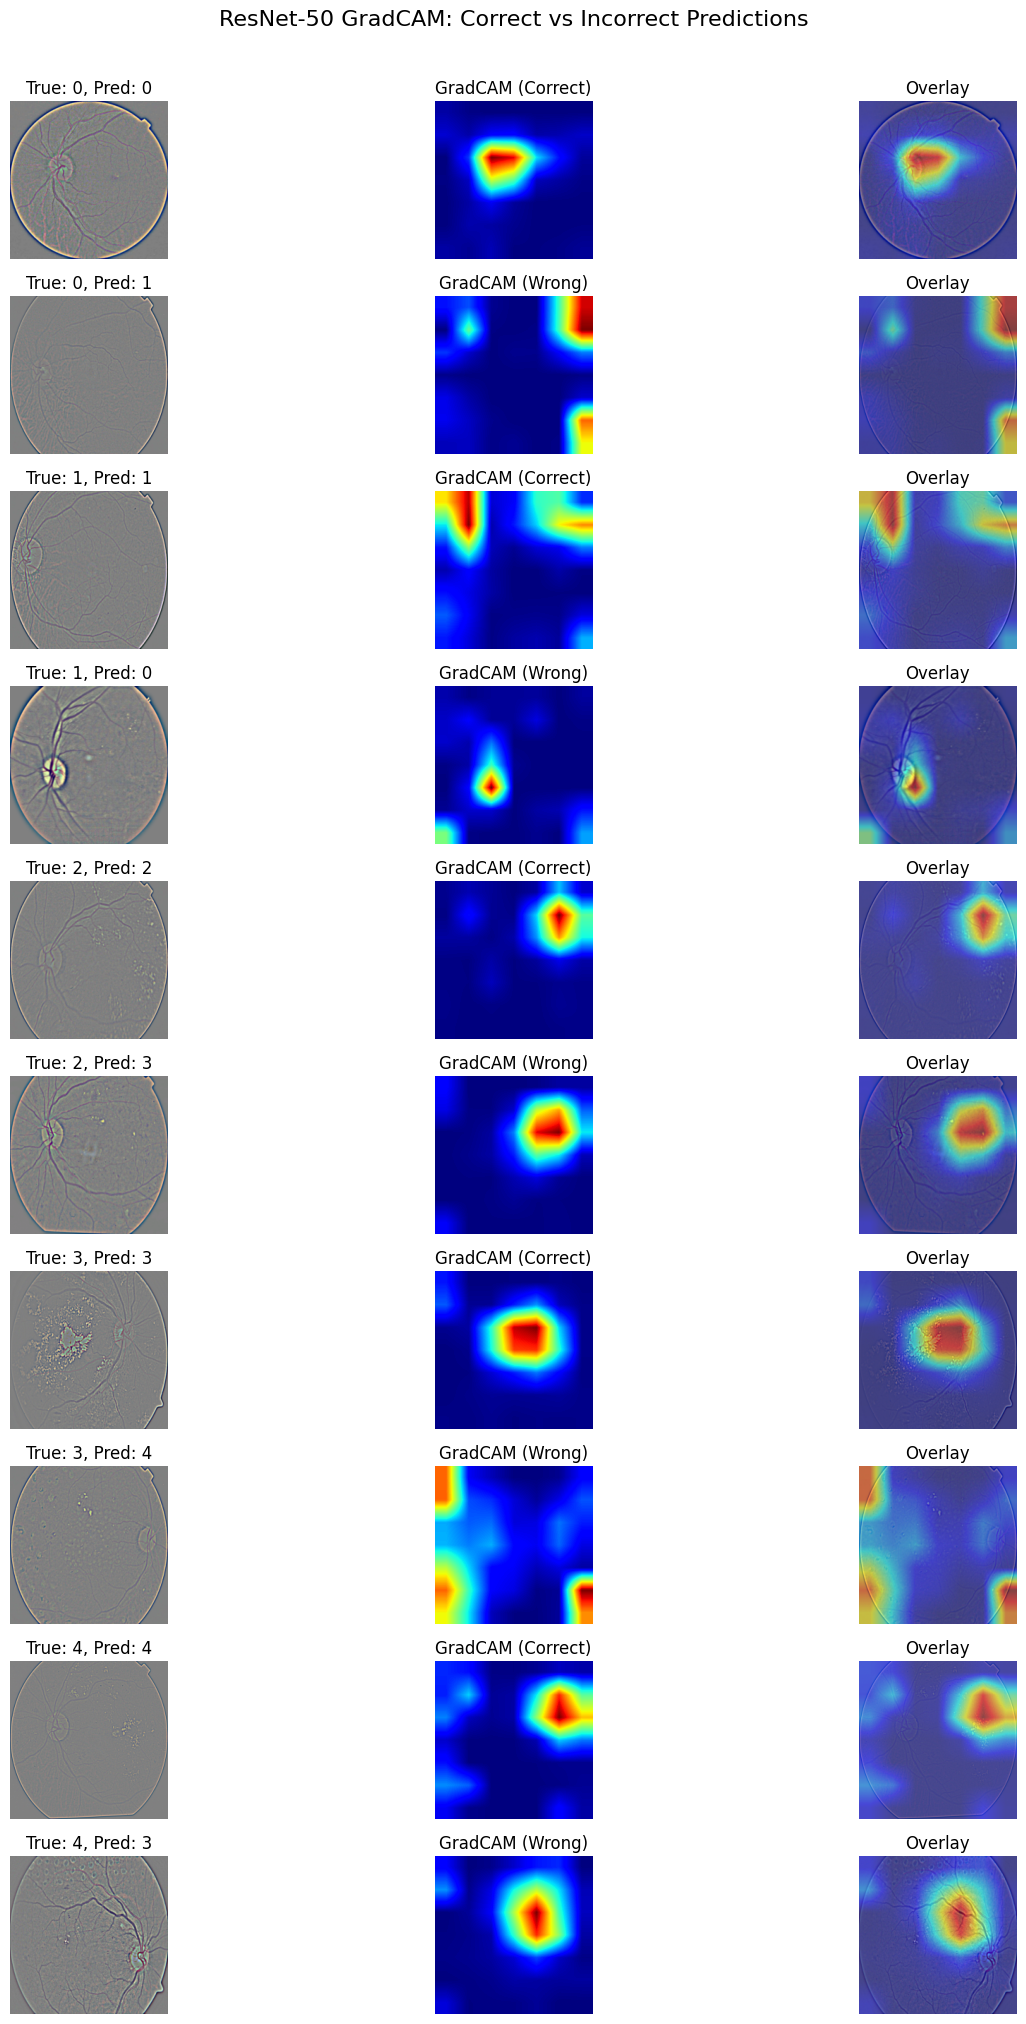

In [19]:
target_layers = [resnet_model.layer4[-1]]
resnet_cams = show_gradcam(resnet_model, 'ResNet-50', x_train, y_train, target_layers)

### EfficientNet

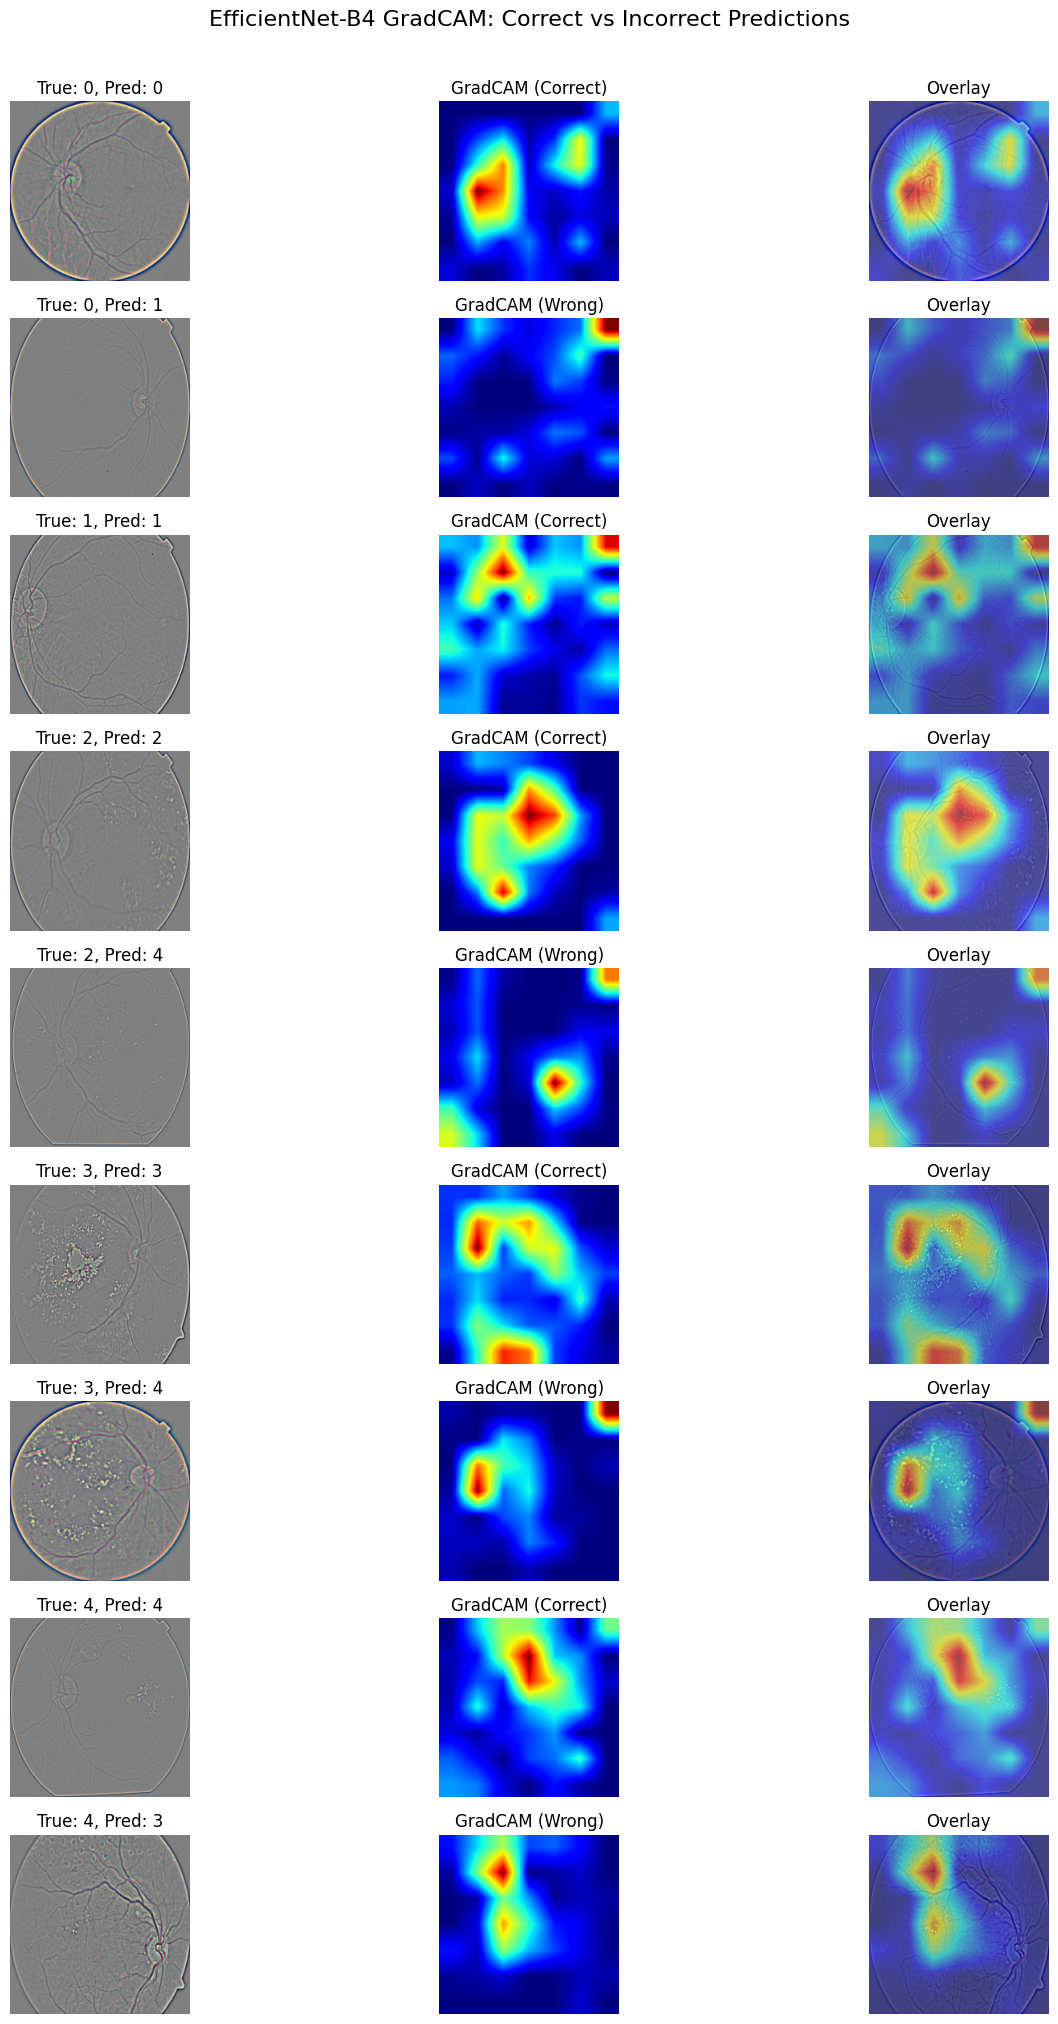

In [20]:
target_layers = [efficientnet_model.features[-1]]
effnet_cams = show_gradcam(efficientnet_model, 'EfficientNet-B4', x_train, y_train, target_layers)